# Imports

In [1]:
import numpyro
numpyro.set_host_device_count(4)

import jax
import jax.numpy as jnp
import numpy as np
print("JAX:", jax.__version__)
print("local device count:", jax.local_device_count())
print("local devices:")
for d in jax.local_devices():
    print("  ", d)
    
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, init_to_value

from likelihood import (
    FD_gaussianlikelihood,
    FD_marg_fullnormal_gaussianlikelihood,
    draw_fluences_fullnormal_gaussmarg,
    FD_marg_halfnormal_nooverlap_gaussianlikelihood,
    draw_fluences_halfnormal_nooverlap_gaussmarg,
)
from model import (
    setup_model,
    make_orthogonal_poly_sed
)

from data import(
    prepare_burst
)

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import arviz as az
import arviz_plots as azp
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

import random

JAX: 0.11.2
local device count: 4
local devices:
   cpu:0
   cpu:1
   cpu:2
   cpu:3


In [2]:
# import sys
# print(sys.executable)  # Should point to your venv path, not /mnt/sw/nix/...

In [3]:
# import tqdm.std

# # Force tqdm to use newlines and flush output instantly for Jupyter
# def line_printer(file):
#     def print_status(s):
#         file.write(s.replace("\r", "") + "\n")
#         file.flush()
#     return print_status

# tqdm.std.status_printer = line_printer

In [4]:
# import sys
# import tqdm.std

# class ThreadSafeStdOut:
#     def __init__(self, stream):
#         self.stream = stream
#     def write(self, s):
#         self.stream.write(s)
#         self.stream.flush()
#     def flush(self):
#         self.stream.flush()

# # Override tqdm's default output file handle
# tqdm.std.tqdm.stqdm_file = ThreadSafeStdOut(sys.stdout)

# Consolidating all code

## Setting Priors

In [5]:
def width_prior_bounds(burst, toa, n_efold_tau=1.0, n_sigma_stds = 3, nu_bot=None, scattering_index=-4.0):
    """
    Loose box bounds for the width and scattering timescale, as entries for the priors dict.

    These are deliberately weak: each parameter alone, at its bound, just fits inside the segment,
    and nothing stops a draw where both are large at once. The joint condition is left to
    `sample_contained_lowestFDbin`, which acts on the evaluated model and so sees the combination.
    The box only prevents the sampler wandering somewhere absurd.

    sigma is bounded so that n_efold widths fit between the arrival time and whichever segment
    edge is closer, since a Gaussian is symmetric. Its floor is the narrowest resolvable width,
    1 / (2 pi f_max) from the Fourier truncation: below that the template has not rolled off
    within the retained bins, so the data do not constrain it. (The sampling interval is not the
    relevant floor -- without truncation the resolvable width would be dt / pi, below dt itself.)

    tau is bounded at the BOTTOM of the band, where the tail is longest, by requiring n_efold
    e-folds between the arrival time and the end of the segment, then converted to tau_ref.

    toa:      arrival time (s, relative to the segment start)
    n_efold_tau:  how many widths or e-folds must fit of the scattering transfer function parameter tau
    n_sigma_stds: how many standard deviations must fit of the pulse width parameter sigma
    nu_bot:   bottom of the band (MHz); taken from the burst's lowest channel if None
    """
    W = burst.n_time * burst.dt
    f_max = float(burst.fourier_freqs[-1])
    nu_bot = float(burst.freq_channels[0][0]) if nu_bot is None else nu_bot

    sigma_min = 1.0 / (2.0 * np.pi * f_max)
    sigma_max = min(toa, W - toa) / n_sigma_stds

    tau_ref_min = 0.0
    tau_bot_max = (W - toa) / n_efold_tau
    tau_ref_max = tau_bot_max * (nu_bot / burst.freq_channels_ref) ** (-scattering_index)

    if not sigma_min < sigma_max:
        raise ValueError(
            f"no width is both resolvable ({sigma_min:.2e} s) and containable ({sigma_max:.2e} s); "
            f"the segment is too short or the Fourier truncation too aggressive."
        )
    print("prior being set with bounds:\nsigma_min =",sigma_min,"\nsigma_max =",
          sigma_max,"\ntau_ref_min =",tau_ref_min,"\ntau_ref_max =",tau_ref_max)
    
    return {
        "sigma_min": sigma_min,
        "sigma_max": sigma_max,
        "tau_ref_min": tau_ref_min,
        "tau_ref_max": tau_ref_max,
    }

In [6]:
def spectral_coeff_bounds(spectral_coeff_map, gamma_range, beta_range):
    """
    Bounds on the sampled c1, c2 of the SED corresponding to a box in the conventional gamma, beta.

    The map is linear, so a box in (gamma, beta) becomes a parallelogram in (c1, c2); this
    returns its bounding box, which is the tightest region expressible as independent uniform
    priors. That admits a little more than intended -- about 8% of the box falls outside the
    gamma-beta limits for a typical basis -- which is harmless when the limits are loose
    catalogue-wide bounds rather than informative constraints.

    Because the map is linear with constant Jacobian, a flat prior on (c1, c2) is also flat on
    (gamma, beta); no correcting factor is needed.
    """
    a1 = spectral_coeff_map["gamma_c1"]
    b2 = spectral_coeff_map["gamma_c2"]
    a2 = spectral_coeff_map["beta_c2"]

    corners = [((g - b2 * (b / a2)) / a1, b / a2) for g in gamma_range for b in beta_range]
    c1s, c2s = zip(*corners)
    
    print("prior being set with bounds:\nc1_min =",min(c1s),"\nc1_max =",
          max(c1s),"\nc2_min =",min(c2s),"\nc2_max =",max(c2s))


    return {
        "c1_min": min(c1s),
        "c1_max": max(c1s),
        "c2_min": min(c2s),
        "c2_max": max(c2s),
    }

In [7]:
def dispersion_prior_bounds(burst, single_pulse_fn):
    """
    Bounds for the residual dispersion measure, as an entry for the priors dict.

    Symmetric about zero, with the magnitude set so that a burst arriving in the middle of the
    segment at the top of the band would sweep to a segment edge by the bottom of the band:

        D_max = W_seg / [ 2 k_D ( nu_bot^epsilon - nu_top^epsilon ) ]

    Beyond that the sweep runs off the end of the segment, which the periodic Fourier-domain
    model would wrap around. The bound is loose in the sense that it ignores the pulse's own
    width and scattering, which also consume the segment; those are bounded separately by
    `width_prior_bounds`, and the joint case is left to the containment penalty.

    The data are assumed already dedispersed, so this is a residual about zero rather than an
    absolute DM; the symmetric range reflects that the residual may be of either sign.

    burst:           the ConditionedData, for the segment length and the band edges
    single_pulse_fn: the model closure, whose `.constants` supply k_DM and epsilon, so the prior
                     and the model cannot disagree about the dispersion law

    Returns {"DM": (lo, hi)}.
    """
    constants = single_pulse_fn.constants

    W_seg = burst.n_time * burst.dt
    nu_bot = float(burst.freq_channels.min())
    nu_top = float(burst.freq_channels.max())

    # Delay difference across the band per unit DM; positive since epsilon is negative
    sweep_per_DM = constants.k_DM * (nu_bot ** constants.epsilon - nu_top ** constants.epsilon)
    D_max = W_seg / (2.0 * sweep_per_DM)

    return {"DM": (-D_max, D_max)}

## Marginalized half normal orthog SED

In [223]:
# -------------------------------------------------------------------
# 1. Data Conditioning
# -------------------------------------------------------------------
# prepare_burst averages the frequency channels, transforms to the Fourier domain, truncates the
# Fourier axis, and builds the orthogonal spectral basis. Everything the model and likelihood
# need comes back in `burst`, so neither has to know how the conditioning was done.
burst = prepare_burst(
    path="/mnt/home/hsiegel/FRBayes/data/event_22154974_BB.npz",
    n_avg=8,                # frequency channels averaged per block
    fd_downsample=4,        # downsampling factor of high frequency FD bins
    toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
    noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
    verbose=True,
)

# -------------------------------------------------------------------
# 2. Model Closure Setup
# -------------------------------------------------------------------
constants_dict = {
    "freq_channels_ref": burst.freq_channels_ref,
    "DM_incoherent": 0.0,          # data are coherently dedispersed, so no intra-channel smearing remains
    "channel_width": burst.channel_width,
}

# Orthogonal spectral basis: sample c1, c2 rather than gamma, beta. Over a factor-of-two band
# x = ln(nu/nu_r) and x^2 are nearly parallel, which makes gamma and beta strongly degenerate;
# P1 and P2 are orthogonal in the metric set by the per-channel weights, and orthogonal to the
# constant, which also decouples them from the fluence.
single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=burst.freq_channels,
    times=burst.times,
    sed_fn=make_orthogonal_poly_sed(*burst.spectral_basis),
    fourier_freqs=burst.fourier_freqs,
)

# containment = dict(
#     extent_max=0.5 * burst.n_time * burst.dt,                        # xi = 0.5, shared with D_max
#     sigma_min=1.0 / (2 * jnp.pi * float(burst.fourier_freqs[-1])),    # narrowest resolvable width
#     bot_over_ref=float(burst.freq_channels[0][0]) / burst.freq_channels_ref,
# )

containment = dict(
    segment_extent=0.5 * burst.n_time * burst.dt,                  # xi = 0.5, shared with D_max
    sigma_min=1.0 / (2 * jnp.pi * float(burst.fourier_freqs[-1])),  # narrowest resolvable width
    bot_over_ref=float(burst.freq_channels[0][0]) / burst.freq_channels_ref,
    ratio_min=0.9,
)

# -------------------------------------------------------------------
# 3. Priors & NUTS Sampling
# -------------------------------------------------------------------
# priors = {
#     "mean_arrival_time": dist.Uniform(0.00115 - 2e-4, 0.00115 + 2e-4),   # (s, relative to segment start)

#     "sigma": dist.Uniform(5e-5, 1e-4),              # intrinsic width (s)
#     "DM": dist.Uniform(-0.1, 0.1),                  # residual DM (pc cm^-3)
#     "tau_ref": dist.Uniform(1e-5, 2e-3),            # scattering timescale at nu_r (s)

#     # Orthogonal basis coefficients, O(1) by construction (unit weighted RMS basis). These are
#     # specific to this burst's basis and are not comparable between bursts; gamma and beta are
#     # recorded as deterministic sites via spectral_coeff_map and are what should be reported.
#     "c1": dist.Uniform(-3.0, 3.0),                  # linear basis coefficient
#     "c2": dist.Uniform(-3.0, 3.0),                  # quadratic basis coefficient
# }
priors = {
    "mean_arrival_time": dist.Uniform(0, burst.times[-1]),  # (s, relative to segment start)
    # "mean_arrival_time": dist.Uniform(0.00115 - 5*2e-4, 0.00115 + 7*2e-4),   # (s, relative to segment start)

    # "sigma": dist.Uniform(5e-5, 1e-4),              # intrinsic width (s)
    "DM": dist.Uniform(-0.0864, 0.0864),                  # residual DM (pc cm^-3)
    # "tau_ref": dist.Uniform(1e-5, 2e-3),            # scattering timescale at nu_r (s)

    # Orthogonal basis coefficients, O(1) by construction (unit weighted RMS basis). These are
    # specific to this burst's basis and are not comparable between bursts; gamma and beta are
    # recorded as deterministic sites via spectral_coeff_map and are what should be reported.
    "c1": dist.Uniform(-3.0, 3.0),                  # linear basis coefficient
    "c2": dist.Uniform(-3.0, 3.0),                  # quadratic basis coefficient
    **width_prior_bounds(burst, toa=1.15e-3)
}
n_pulses = 1
s_opt = 100.0

num_warmup = 1000
num_samples = 200
num_chains = 1

kernel = NUTS(FD_marg_halfnormal_nooverlap_gaussianlikelihood, dense_mass=True)
mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains,
            chain_method="parallel")

# Fixed master key seed for reproducible sampling across runs
key_sampler, key_fluences = jax.random.split(jax.random.PRNGKey(7))

mcmc.run(
    key_sampler,
    data_fd=burst.data_fd,
    sigma_noise_fd=burst.sigma_noise_fd,
    n_pulses=n_pulses,
    priors=priors,
    single_pulse_fn=single_pulse_fn,
    s_opt=s_opt,
    spectral_coeff_map=burst.spectral_coeff_map,
    containment=None,
    extra_fields=("num_steps", "accept_prob", "diverging", "potential_energy")
)

# # -------------------------------------------------------------------
# # 4. Extract Posteriors & Recover Fluences
# # -------------------------------------------------------------------
# samples = dict(mcmc.get_samples())
# extra = mcmc.get_extra_fields()

# # The half-normal marginalization integrates the fluences out, so they are drawn afterwards from
# # their exact conditional: a normal truncated to A > 0, independent across components under the
# # non-overlap assumption. Positivity is built into the prior, so every draw is valid.
# samples["A"] = draw_fluences_halfnormal_nooverlap_gaussmarg(
#     samples["snr_opt"], samples["snr_mf"], s_opt, key_fluences
# )

#mcmc_data = az.from_dict(posterior={k: jnp.asarray(v)[None, ...] for k, v in samples.items()})

820 good channels -> 102 blocks of 8 (4 dropped); block span median 3.125 MHz, max 4.688 MHz
noise estimated from 65 of 329 time bins (first 20% of the segment)
Fourier truncation: keeping 40 of 165 bins (up to 11.9 kHz of 48.7 kHz)
weighted mean frequency 460.7 MHz, reference frequency 453.2 MHz
prior being set with bounds:
sigma_min = 1.3404665608610986e-05 
sigma_max = 0.00038333333333333334 
tau_ref_min = 0.0 
tau_ref_max = 0.0013766223072632156


AttributeError: 'float' object has no attribute 'expand'

In [101]:
# -------------------------------------------------------------------
# 4. Extract Posteriors
# -------------------------------------------------------------------
samples = mcmc.get_samples()
extra = mcmc.get_extra_fields()
mcmc_data = az.from_numpyro(mcmc, log_likelihood={}, posterior_predictive={})

In [102]:
mcmc_data = az.from_numpyro(mcmc, log_likelihood={}, posterior_predictive={})

In [103]:
az.summary(mcmc_data, round_to=3)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
DM[0],-7.000000e-03,0.000000e+00,-7.000000e-03,-7.000000e-03,153.418,129.280,NaN,0.000000e+00,0.000000e+00
beta[0],-1.425800e+01,7.290000e-01,-1.536800e+01,-1.311400e+01,192.883,123.101,NaN,5.400000e-02,6.900000e-02
c1[0],-8.520000e-01,1.400000e-02,-8.750000e-01,-8.310000e-01,238.226,92.053,NaN,1.000000e-03,1.000000e-03
c2[0],-2.590000e-01,1.300000e-02,-2.790000e-01,-2.380000e-01,192.883,123.101,NaN,1.000000e-03,1.000000e-03
gamma[0],-5.176000e+00,7.500000e-02,-5.286000e+00,-5.064000e+00,282.155,129.114,NaN,4.000000e-03,9.000000e-03
"gram[0, 0]",4.026655e+10,5.325970e+08,3.942145e+10,4.109558e+10,227.375,130.738,NaN,3.587761e+07,3.272975e+07
mean_arrival_time[0],1.000000e-03,0.000000e+00,1.000000e-03,1.000000e-03,179.938,160.960,NaN,0.000000e+00,0.000000e+00
rho_mf[0],3.888706e+07,2.573368e+05,3.847696e+07,3.928601e+07,227.316,130.738,NaN,1.735544e+04,1.582964e+04
sigma[0],0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,172.679,158.287,NaN,0.000000e+00,0.000000e+00
snr_mf[0],1.937950e+02,1.000000e-02,1.937790e+02,1.938060e+02,78.102,88.105,NaN,1.000000e-03,1.000000e-03


In [104]:
ex = mcmc.get_extra_fields()
ns = jnp.array(ex["num_steps"])                    # (chain, draw) with num_chains > 1
n_chains = ns.shape[0] if ns.ndim > 1 else 1
ns = ns.reshape(n_chains, -1)
acc = jnp.array(ex["accept_prob"]).reshape(n_chains, -1)
div = jnp.array(ex["diverging"]).reshape(n_chains, -1)
pe = jnp.array(ex["potential_energy"]).reshape(n_chains, -1)
step = jnp.atleast_1d(mcmc.last_state.adapt_state.step_size)

for c in range(n_chains):
    print(f"chain {c}: grads/sample mean {ns[c].mean():5.1f} max {ns[c].max():4d} | "
          f"max depth {100*jnp.mean(ns[c] >= 2**10 - 1):4.1f}% | "
          f"accept {acc[c].mean():.3f} | div {int(div[c].sum())}/{ns.shape[1]} | "
          f"step {float(step[c % step.size]):.3e} | "
          f"U mean {pe[c].mean():9.1f} sd {pe[c].std():.2f}")

chain 0: grads/sample mean   8.7 max   63 | max depth  0.0% | accept 0.926 | div 0/200 | step 3.790e-01 | U mean  -18762.7 sd 1.86


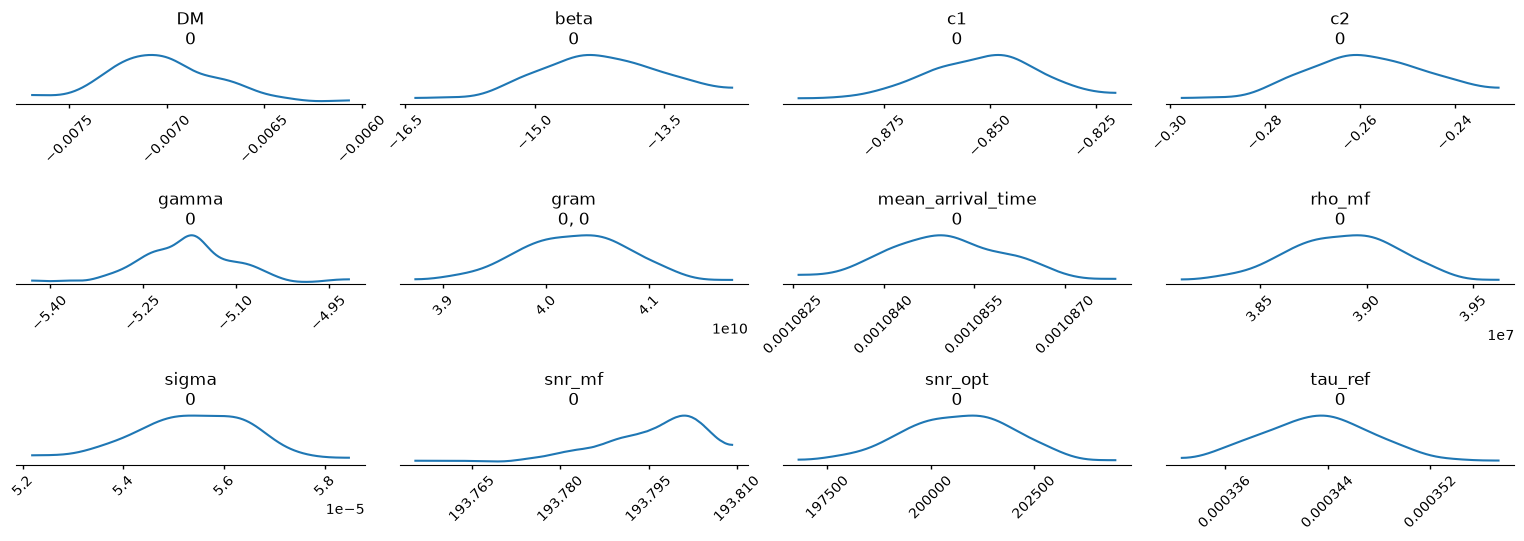

In [105]:
axes = azp.plot_dist(mcmc_data, stats=None)
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))  # Limit to 4 ticks max
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.subplots_adjust(hspace=2.5)

# Remove all "mean" text annotations across all subplots
for ax in plt.gcf().axes:
    for text in list(ax.texts):
        if "mean" in text.get_text():
            text.remove()
            # Remove horizontal interval lines (they only have 2 x-data points)
    for line in list(ax.lines):
        if len(line.get_xdata()) <= 2:
            line.remove()
            # 3. Remove point estimate dots
    for collection in list(ax.collections):
        collection.remove()

plt.draw() 

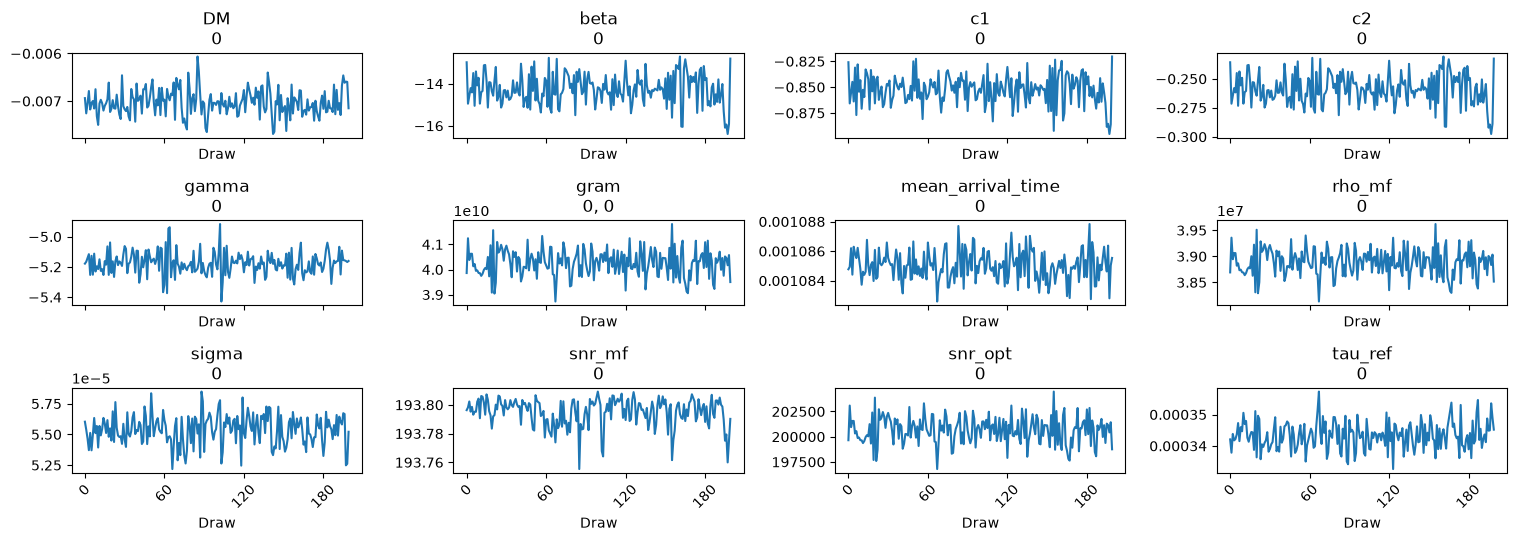

In [106]:
azp.plot_trace(mcmc_data)

# 2. Clean up x-axis tick clutter across all generated subplots
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [107]:
# -------------------------------------------------------------------
# 4. Reconstruct Fluences
# -------------------------------------------------------------------

fluences = draw_fluences_halfnormal_nooverlap_gaussmarg(
    snr_opt=samples["snr_opt"],
    snr_mf=samples["snr_mf"],
    s_opt=s_opt,
    key=key_fluences,
)

Plotting for Posterior Draw #189


/tmp/ipykernel_2056548/1393557241.py:117: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


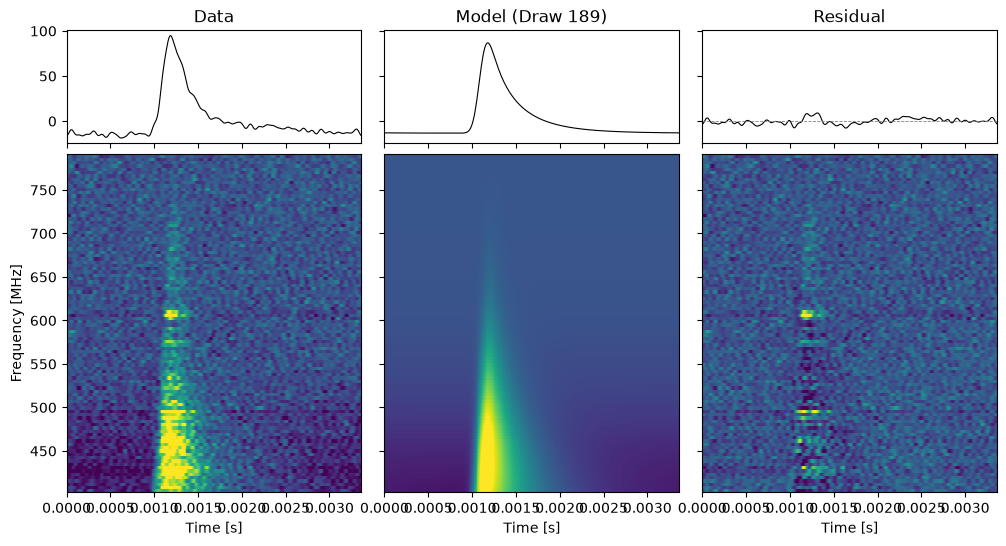

In [108]:
# -------------------------------------------------------------------
# 1. Extract a Random Posterior Draw & Evaluate Forward Model
# -------------------------------------------------------------------
# samples = mcmc.get_samples()
num_draws = len(next(iter(samples.values())))

# Pick a draw index using JAX random
key = jax.random.PRNGKey(0)
draw_idx = int(jax.random.randint(key, shape=(), minval=0, maxval=num_draws))
print(f"Plotting for Posterior Draw #{draw_idx}")

# Extract parameters for the chosen draw directly as JAX scalars
test_params = {
    "mean_arrival_time": samples["mean_arrival_time"][draw_idx],
    "sigma": samples["sigma"][draw_idx],
    "DM": samples["DM"][draw_idx],
    "tau_ref": samples["tau_ref"][draw_idx],
    "c1": samples["c1"][draw_idx],
    "c2": samples["c2"][draw_idx],
}
A_scale = fluences[draw_idx]

# Extract amplitude scale from posterior ('gram' or fallback to default)
# A_scale = (
#     samples["gram"][draw_idx] if "gram" in samples else fluences[draw_idx]
# )

# Evaluate model in Fourier domain and transform to Time Domain
# The data and model now live on the truncated Fourier axis, so they must be placed back at
# their original bin indices before inverting; irfft(n=Nseg) on the truncated array would
# reinterpret bin k as frequency k/(Nseg dt), which is not where it came from.
Nseg = burst.n_time
dt=burst.dt
data_reshaped_FFT = burst.data_fd
n_full = Nseg // 2 + 1
pad = lambda X: jnp.zeros((X.shape[0], n_full), X.dtype).at[:, 1:1 + X.shape[-1]].set(X)

M_FD = single_pulse_fn(test_params) * A_scale
M_TD = (1.0 / dt) * jnp.fft.irfft(pad(M_FD), n=Nseg, axis=-1)
data_TD = (1.0 / dt) * jnp.fft.irfft(pad(data_reshaped_FFT), n=Nseg, axis=-1)

data_TD_plot = data_TD
model_TD_plot = M_TD
time_plot = burst.times
freq_plot = jnp.squeeze(burst.freq_channels)

# -------------------------------------------------------------------
# 2. Residuals & Frequency Collapsed Time Series
# -------------------------------------------------------------------
resid_TD_plot = data_TD_plot - model_TD_plot

# Frequency-summed time series
data_ts = jnp.nansum(data_TD_plot, axis=0)
model_ts = jnp.nansum(model_TD_plot, axis=0)
resid_ts = data_ts - model_ts

# Shared robust color limits using jnp
vmin, vmax = jnp.nanpercentile(data_TD_plot, jnp.array([1.0, 99.0]))

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: Frequency-summed time series ---
ax_ts_data.plot(time_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(time_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(time_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_TD_plot, **imshow_kwargs)
ax_wf_model.imshow(model_TD_plot, **imshow_kwargs)
ax_wf_resid.imshow(resid_TD_plot, **imshow_kwargs)

# --- Formatting ---
ax_ts_data.set_title("Data")
ax_ts_model.set_title(f"Model (Draw {draw_idx})")
ax_ts_resid.set_title("Residual")

ax_wf_data.set_xlabel("Time [s]")
ax_wf_model.set_xlabel("Time [s]")
ax_wf_resid.set_xlabel("Time [s]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

Max Data abs : 39.16236
Max Model abs: 34.716522
whitened residual sd: 1.321  (expect 1)


/tmp/ipykernel_2056548/785051423.py:103: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


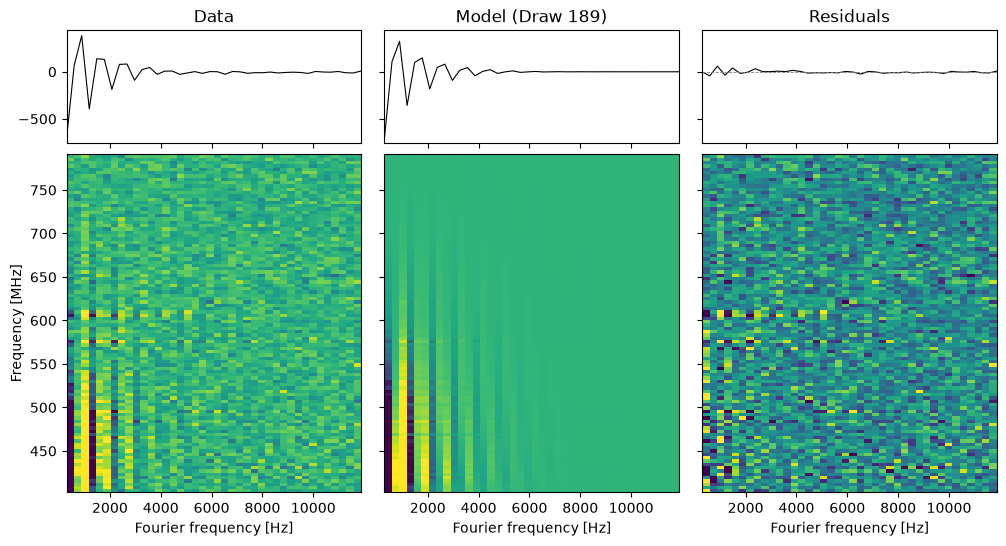

In [109]:
# -------------------------------------------------------------------
# 1. Forward model evaluation, Fourier domain
# -------------------------------------------------------------------
M_FD = single_pulse_fn(test_params) * A_scale

# data_reshaped_FFT and the model already live on the truncated Fourier axis, which is exactly
# the set of bins the likelihood uses, so nothing needs slicing here.
sigma_bins = jnp.broadcast_to(burst.sigma_noise_fd, data_reshaped_FFT.shape)

# Whitened, so all three panels are in units of sigma and the residual should be N(0, 1) noise
data_FD_plot = (data_reshaped_FFT / sigma_bins).real
model_FD_plot = (M_FD / sigma_bins).real
resid_FD_plot = data_FD_plot - model_FD_plot

fourier_freqs = burst.fourier_freqs
fourier_plot = jnp.asarray(fourier_freqs).reshape(-1)
freq_plot = jnp.squeeze(burst.freq_channels)

print("Max Data abs :", jnp.max(jnp.abs(data_FD_plot)))
print("Max Model abs:", jnp.max(jnp.abs(model_FD_plot)))
print(f"whitened residual sd: {float(jnp.std(resid_FD_plot)):.3f}  (expect 1)")

# -------------------------------------------------------------------
# 2. Channel-summed spectra
# -------------------------------------------------------------------
data_ts = jnp.nansum(data_FD_plot, axis=0)
model_ts = jnp.nansum(model_FD_plot, axis=0)
resid_ts = data_ts - model_ts

# Data & Model limits
vmin, vmax = jnp.nanpercentile(data_FD_plot, jnp.array([1.0, 99.0]))

# Independent zero-centered limits for Residuals
vmax_res = jnp.nanpercentile(jnp.abs(resid_FD_plot), 99.0)

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: channel-summed spectra ---
ax_ts_data.plot(fourier_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(fourier_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(fourier_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_data_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(fourier_plot[0], fourier_plot[-1], freq_plot[0], freq_plot[-1]),
)

imshow_resid_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=-vmax_res,
    vmax=vmax_res,
    extent=(fourier_plot[0], fourier_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_FD_plot, **imshow_data_kwargs)
ax_wf_model.imshow(model_FD_plot, **imshow_data_kwargs)
ax_wf_resid.imshow(resid_FD_plot, **imshow_resid_kwargs)

# --- Formatting ---
ax_ts_model.set_title(f"Model (Draw {draw_idx})")
ax_ts_data.set_title("Data")
ax_ts_resid.set_title("Residuals")

ax_wf_data.set_xlabel("Fourier frequency [Hz]")
ax_wf_model.set_xlabel("Fourier frequency [Hz]")
ax_wf_resid.set_xlabel("Fourier frequency [Hz]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

## Unmarg orthog SED

In [12]:
# -------------------------------------------------------------------
# 1. Data Conditioning
# -------------------------------------------------------------------
# prepare_burst averages the frequency channels, transforms to the Fourier domain, truncates the
# Fourier axis, and builds the orthogonal spectral basis. Everything the model and likelihood
# need comes back in `burst`, so neither has to know how the conditioning was done.
burst = prepare_burst(
    path="/mnt/home/hsiegel/FRBayes/data/event_22154974_BB.npz",
    n_avg=8,                # frequency channels averaged per block
    fd_downsample=4,        # downsampling factor of high frequency FD bins
    toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
    noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
    verbose=True,
)

# -------------------------------------------------------------------
# 2. Model Closure Setup
# -------------------------------------------------------------------
constants_dict = {
    "freq_channels_ref": burst.freq_channels_ref,
    "DM_incoherent": 0.0,          # data are coherently dedispersed, so no intra-channel smearing remains
    "channel_width": burst.channel_width,
}

# Orthogonal spectral basis: sample c1, c2 rather than gamma, beta. Over a factor-of-two band
# x = ln(nu/nu_r) and x^2 are nearly parallel, which makes gamma and beta strongly degenerate;
# P1 and P2 are orthogonal in the metric set by the per-channel weights, and orthogonal to the
# constant, which also decouples them from the fluence.
single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=burst.freq_channels,
    times=burst.times,
    sed_fn=make_orthogonal_poly_sed(*burst.spectral_basis),
    fourier_freqs=burst.fourier_freqs,
)

# A second closure on just the two frequencies the wraparound penalty needs: the segment's
# fundamental f1 = 1 / W_seg and half of it. The likelihood never sees this grid.
f1 = 1.0 / (burst.n_time * burst.dt)

single_pulse_fn_low = setup_model(
    constants_dict=constants_dict,
    freqs_channels=burst.freq_channels,
    times=burst.times,
    sed_fn=make_orthogonal_poly_sed(*burst.spectral_basis),
    fourier_freqs=jnp.array([f1 / 2, f1]),
)

# containment = dict(
#     n_sigma= 3.0,
#     n_tau = 1.0,
#     extent_max=0.5 * burst.n_time * burst.dt,                        # xi = 0.5, shared with D_max
#     sigma_min=1.0 / (2 * jnp.pi * float(burst.fourier_freqs[-1])),    # narrowest resolvable width
#     bot_over_ref=float(burst.freq_channels[0][0]) / burst.freq_channels_ref,
# )

containment_FD = dict(
    single_pulse_fn_low=single_pulse_fn_low,   # the two-frequency closure
    inv_var=1.0 / burst.sigma_noise_fd ** 2,   # (nfreq, 1)
    ratio_min=0.9,                             # how much of the envelope must survive at f1
    K=100.0,                                   # penalty at ratio = 0, in nats
    w=0.01,                                    # sharpness of the transition
)

# -------------------------------------------------------------------
# 3. Priors & NUTS Sampling
# -------------------------------------------------------------------

width_prior = width_prior_bounds(burst, toa=1.15e-3)
spectral_prior = spectral_coeff_bounds(burst.spectral_coeff_map, [-10,200],[-200,10])
DM_prior = dispersion_prior_bounds(burst,single_pulse_fn)
s_opt = 100

priors = {
    # "mean_arrival_time": dist.Uniform(0.00115 - 5*2e-4, 0.00115 + 7*2e-4),   # (s, relative to segment start)
    "mean_arrival_time": dist.Uniform(0, burst.times[-1]),   # (s, relative to segment start)

    # "sigma": dist.Uniform(5e-5, 1e-4),              # intrinsic width (s)
    "DM": dist.Uniform(DM_prior["DM"][0], DM_prior["DM"][1]),                  # residual DM (pc cm^-3)
    # "tau_ref": dist.Uniform(1e-5, 2e-3),            # scattering timescale at nu_r (s)

    # Orthogonal basis coefficients, O(1) by construction (unit weighted RMS basis). These are
    # specific to this burst's basis and are not comparable between bursts; gamma and beta are
    # recorded as deterministic sites via spectral_coeff_map and are what should be reported.
    "c1": dist.Uniform(spectral_prior["c1_min"], spectral_prior["c1_max"]),                  # linear basis coefficient
    "c2": dist.Uniform(spectral_prior["c2_min"], spectral_prior["c2_max"]),                  # quadratic basis coefficient
     # "A": dist.Uniform(1e-5, 1e-2),
    #"A_snr": dist.Uniform(0,250),
    "A_snr": dist.HalfNormal(s_opt),
    "sigma": dist.Uniform(width_prior["sigma_min"],width_prior["sigma_max"]),   # floor from the Fourier truncation
    "tau_ref": dist.Uniform(width_prior["tau_ref_min"],width_prior["tau_ref_max"]),
}

n_pulses = 1

num_warmup = 1000
num_samples = 200
num_chains = 1

# Fixed master key seed for reproducible sampling across runs
key_sampler, key_fluences = jax.random.split(jax.random.PRNGKey(3))


#initialization of sampler
W = burst.n_time * burst.dt
init = init_to_value(values={
    "sigma": jnp.array([width_prior["sigma_max"]*0.9]),
    #"sigma": jnp.array([(width_prior["sigma_min"]+width_prior["sigma_max"])/2]),
    "tau_ref": jnp.array([5*burst.dt]),
    "mean_arrival_time": jnp.array([0.5 * W]),
    "DM": jnp.array([0]),
    "c1": jnp.array([0]),
    "c2": jnp.array([0])
})


# kernel = NUTS(FD_gaussianlikelihood, dense_mass=True)
kernel = NUTS(FD_gaussianlikelihood, dense_mass=True, init_strategy=init)

mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains,
            chain_method="parallel")

mcmc.run(
    key_sampler,
    data_fd=burst.data_fd,
    sigma_noise_fd=burst.sigma_noise_fd,
    n_pulses=n_pulses,
    priors=priors,
    single_pulse_fn=single_pulse_fn,
    spectral_coeff_map=burst.spectral_coeff_map,
    containment_FD=containment_FD,
    extra_fields=("num_steps", "accept_prob", "diverging", "potential_energy")
)

# # -------------------------------------------------------------------
# # 4. Extract Posteriors & Recover Fluences
# # -------------------------------------------------------------------
# samples = dict(mcmc.get_samples())
# extra = mcmc.get_extra_fields()

# # The half-normal marginalization integrates the fluences out, so they are drawn afterwards from
# # their exact conditional: a normal truncated to A > 0, independent across components under the
# # non-overlap assumption. Positivity is built into the prior, so every draw is valid.
# samples["A"] = draw_fluences_halfnormal_nooverlap_gaussmarg(
#     samples["snr_opt"], samples["snr_mf"], s_opt, key_fluences
# )

#mcmc_data = az.from_dict(posterior={k: jnp.asarray(v)[None, ...] for k, v in samples.items()})

820 good channels -> 102 blocks of 8 (4 dropped); block span median 3.125 MHz, max 4.688 MHz
noise estimated from 65 of 329 time bins (first 20% of the segment)
Fourier truncation: keeping 40 of 165 bins (up to 11.9 kHz of 48.7 kHz)
weighted mean frequency 460.7 MHz, reference frequency 453.2 MHz
prior being set with bounds:
sigma_min = 1.3404665608610986e-05 
sigma_max = 0.00038333333333333334 
tau_ref_min = 0.0 
tau_ref_max = 0.0013766223072632156
prior being set with bounds:
c1_min = -5.25784 
c1_max = 21.606956 
c2_min = -3.6313496 
c2_max = 0.18156748
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


  0%|          | 0/1200 [00:00<?, ?it/s]

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


sample: 100%|██████████| 1200/1200 [00:07<00:00, 167.75it/s, 15 steps of size 3.28e-01. acc. prob=0.93]


In [225]:
# -------------------------------------------------------------------
# 4. Extract Posteriors
# -------------------------------------------------------------------
samples = mcmc.get_samples()
extra = mcmc.get_extra_fields()
mcmc_data = az.from_numpyro(mcmc, log_likelihood={}, posterior_predictive={})

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


In [226]:
mcmc_data = az.from_numpyro(mcmc, log_likelihood={}, posterior_predictive={})

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


In [227]:
az.summary(mcmc_data, round_to=3)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
A[0],0.001,0.000,0.001,0.001,197.243,139.965,NaN,0.000,0.000
A_snr[0],193.707,0.974,191.960,195.038,290.155,169.264,NaN,0.059,0.079
DM[0],-0.007,0.000,-0.007,-0.007,165.949,150.483,NaN,0.000,0.000
beta[0],-14.410,0.784,-15.737,-13.162,157.224,118.811,NaN,0.063,0.053
c1[0],-0.854,0.013,-0.874,-0.836,153.029,120.387,NaN,0.001,0.001
c2[0],-0.262,0.014,-0.286,-0.239,157.224,118.811,NaN,0.001,0.001
gamma[0],-5.163,0.075,-5.286,-5.050,284.956,171.080,NaN,0.005,0.005
mean_arrival_time[0],0.001,0.000,0.001,0.001,230.037,142.086,NaN,0.000,0.000
sigma[0],0.000,0.000,0.000,0.000,142.625,110.786,NaN,0.000,0.000
snr_opt[0],201183.922,1513.039,198979.649,203778.835,184.407,148.732,NaN,112.513,118.232


In [228]:
ex = mcmc.get_extra_fields()
ns = jnp.array(ex["num_steps"])                    # (chain, draw) with num_chains > 1
n_chains = ns.shape[0] if ns.ndim > 1 else 1
ns = ns.reshape(n_chains, -1)
acc = jnp.array(ex["accept_prob"]).reshape(n_chains, -1)
div = jnp.array(ex["diverging"]).reshape(n_chains, -1)
pe = jnp.array(ex["potential_energy"]).reshape(n_chains, -1)
step = jnp.atleast_1d(mcmc.last_state.adapt_state.step_size)

for c in range(n_chains):
    print(f"chain {c}: grads/sample mean {ns[c].mean():5.1f} max {ns[c].max():4d} | "
          f"max depth {100*jnp.mean(ns[c] >= 2**10 - 1):4.1f}% | "
          f"accept {acc[c].mean():.3f} | div {int(div[c].sum())}/{ns.shape[1]} | "
          f"step {float(step[c % step.size]):.3e} | "
          f"U mean {pe[c].mean():9.1f} sd {pe[c].std():.2f}")

chain 0: grads/sample mean   9.5 max   19 | max depth  0.0% | accept 0.905 | div 0/200 | step 3.749e-01 | U mean    7136.3 sd 1.84


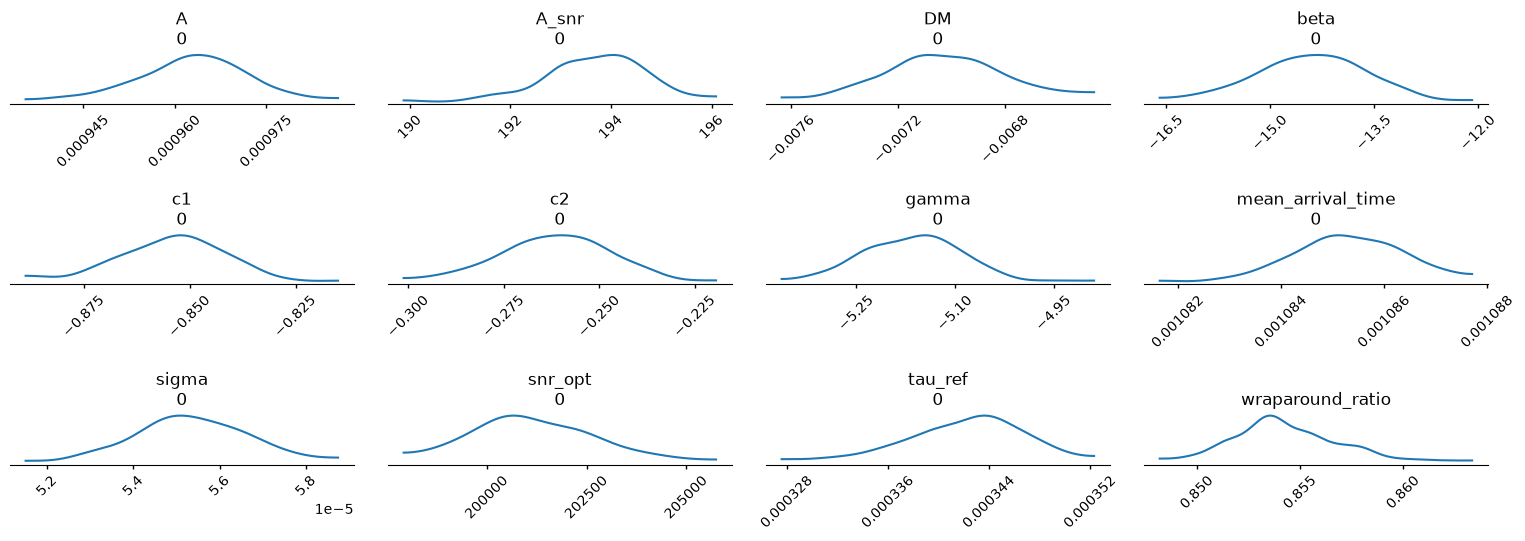

In [229]:
axes = azp.plot_dist(mcmc_data, stats=None)
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))  # Limit to 4 ticks max
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.subplots_adjust(hspace=2.5)

# Remove all "mean" text annotations across all subplots
for ax in plt.gcf().axes:
    for text in list(ax.texts):
        if "mean" in text.get_text():
            text.remove()
            # Remove horizontal interval lines (they only have 2 x-data points)
    for line in list(ax.lines):
        if len(line.get_xdata()) <= 2:
            line.remove()
            # 3. Remove point estimate dots
    for collection in list(ax.collections):
        collection.remove()

plt.draw() 

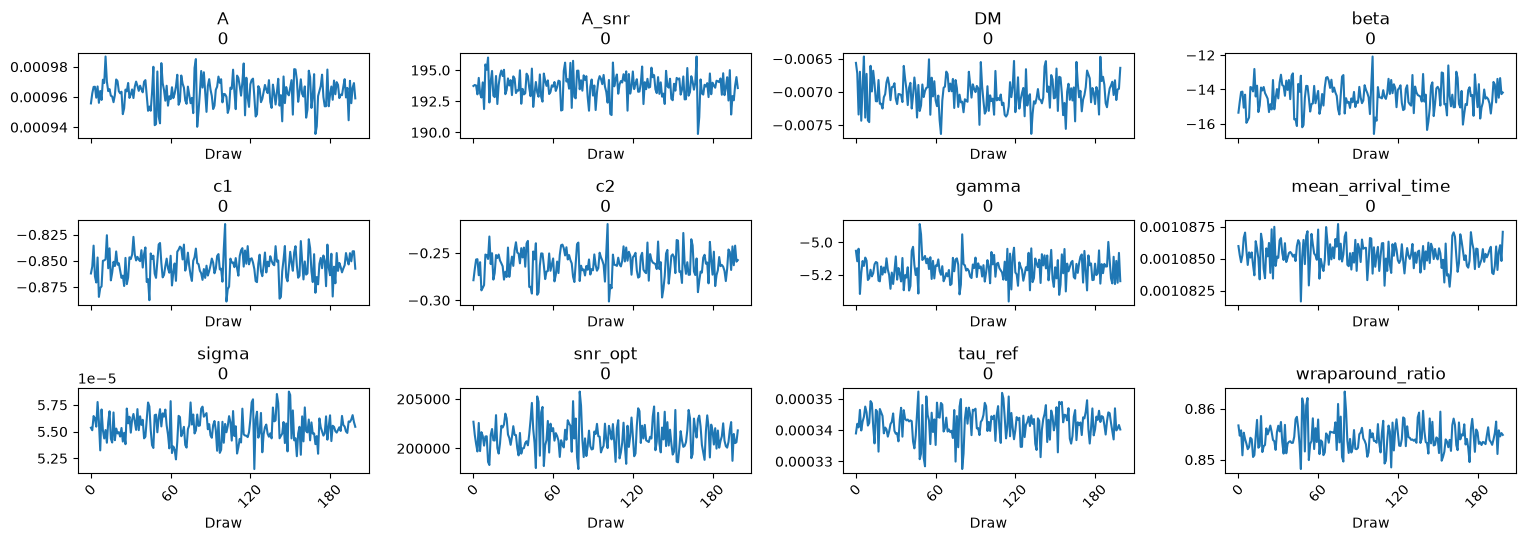

In [230]:
azp.plot_trace(mcmc_data)

# 2. Clean up x-axis tick clutter across all generated subplots
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Plotting for Posterior Draw #196


/tmp/ipykernel_2056548/2219313781.py:127: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


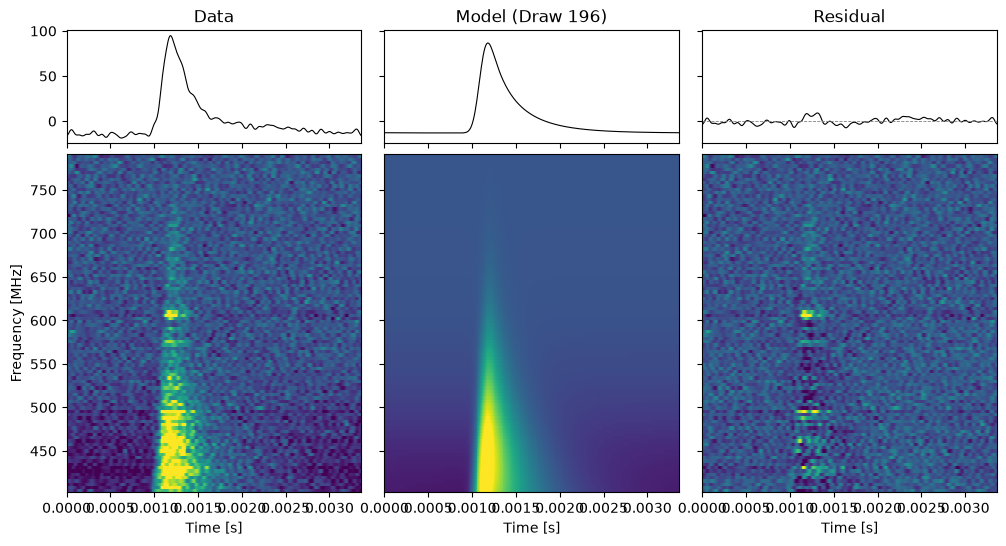

In [235]:
# -------------------------------------------------------------------
# 1. Extract a Random Posterior Draw & Evaluate Forward Model
# -------------------------------------------------------------------
# samples = mcmc.get_samples()
num_draws = len(next(iter(samples.values())))

# Pick a draw index using JAX random
key = jax.random.PRNGKey(1)
draw_idx = int(jax.random.randint(key, shape=(), minval=0, maxval=num_draws))
print(f"Plotting for Posterior Draw #{draw_idx}")

# Extract parameters for the chosen draw directly as JAX scalars
test_params = {
    "mean_arrival_time": samples["mean_arrival_time"][draw_idx],
    "sigma": samples["sigma"][draw_idx],
    "DM": samples["DM"][draw_idx],
    "tau_ref": samples["tau_ref"][draw_idx],
    "c1": samples["c1"][draw_idx],
    "c2": samples["c2"][draw_idx],
    "A": samples["A"][draw_idx]
}
# test_params={'sigma': width_prior["sigma_max"]*0.9,#0.00019837, 
#              'tau_ref': 5*burst.dt, 
#              'mean_arrival_time':0.00168448,
#              'DM': 0, 
#              'c1': 0,
#              'c2': 0,
#              "A": samples["A"][draw_idx]}


# Extract amplitude scale from posterior ('gram' or fallback to default)
# A_scale = (
#     samples["gram"][draw_idx] if "gram" in samples else fluences[draw_idx]
# )

# Evaluate model in Fourier domain and transform to Time Domain
# The data and model now live on the truncated Fourier axis, so they must be placed back at
# their original bin indices before inverting; irfft(n=Nseg) on the truncated array would
# reinterpret bin k as frequency k/(Nseg dt), which is not where it came from.
Nseg = burst.n_time
dt=burst.dt
data_reshaped_FFT = burst.data_fd
n_full = Nseg // 2 + 1
pad = lambda X: jnp.zeros((X.shape[0], n_full), X.dtype).at[:, 1:1 + X.shape[-1]].set(X)

M_FD = single_pulse_fn(test_params)
M_TD = (1.0 / dt) * jnp.fft.irfft(pad(M_FD), n=Nseg, axis=-1)
data_TD = (1.0 / dt) * jnp.fft.irfft(pad(data_reshaped_FFT), n=Nseg, axis=-1)

data_TD_plot = data_TD
model_TD_plot = M_TD
time_plot = burst.times
freq_plot = jnp.squeeze(burst.freq_channels)

# -------------------------------------------------------------------
# 2. Residuals & Frequency Collapsed Time Series
# -------------------------------------------------------------------
resid_TD_plot = data_TD_plot - model_TD_plot

# Frequency-summed time series
data_ts = jnp.nansum(data_TD_plot, axis=0)
model_ts = jnp.nansum(model_TD_plot, axis=0)
resid_ts = data_ts - model_ts

# Shared robust color limits using jnp
vmin, vmax = jnp.nanpercentile(data_TD_plot, jnp.array([1.0, 99.0]))

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: Frequency-summed time series ---
ax_ts_data.plot(time_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(time_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(time_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_TD_plot, **imshow_kwargs)
ax_wf_model.imshow(model_TD_plot, **imshow_kwargs)
ax_wf_resid.imshow(resid_TD_plot, **imshow_kwargs)

# --- Formatting ---
ax_ts_data.set_title("Data")
ax_ts_model.set_title(f"Model (Draw {draw_idx})")
ax_ts_resid.set_title("Residual")
# ax_ts_data.axvline(0.00115 - 5*2e-4)
# ax_ts_data.axvline(0.00115 + 7*2e-4)

ax_wf_data.set_xlabel("Time [s]")
ax_wf_model.set_xlabel("Time [s]")
ax_wf_resid.set_xlabel("Time [s]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

Max Data abs : 39.16236
Max Model abs: 34.152946
whitened residual sd: 1.322  (expect 1)


/tmp/ipykernel_2056548/1186744876.py:103: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


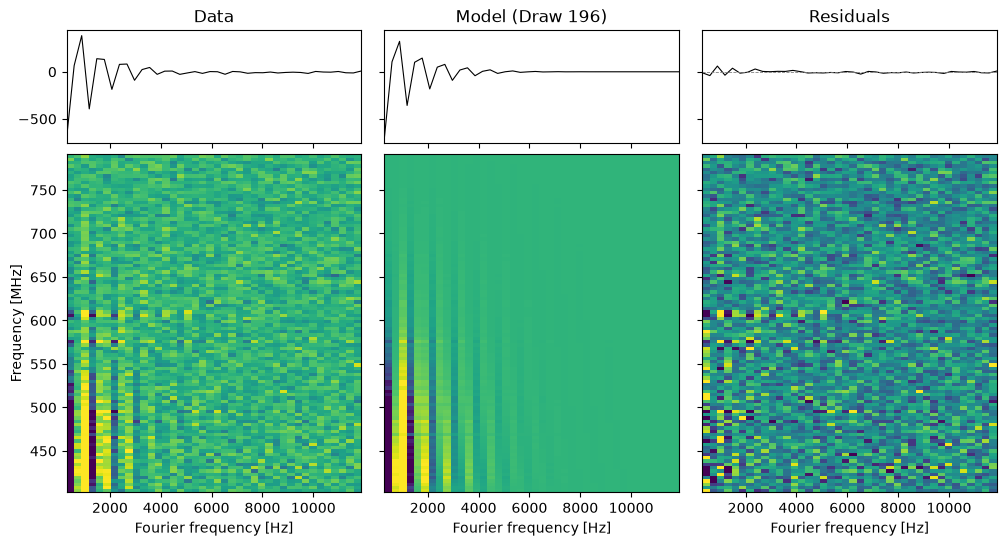

In [233]:
# -------------------------------------------------------------------
# 1. Forward model evaluation, Fourier domain
# -------------------------------------------------------------------
M_FD = single_pulse_fn(test_params)

# data_reshaped_FFT and the model already live on the truncated Fourier axis, which is exactly
# the set of bins the likelihood uses, so nothing needs slicing here.
sigma_bins = jnp.broadcast_to(burst.sigma_noise_fd, data_reshaped_FFT.shape)

# Whitened, so all three panels are in units of sigma and the residual should be N(0, 1) noise
data_FD_plot = (data_reshaped_FFT / sigma_bins).real
model_FD_plot = (M_FD / sigma_bins).real
resid_FD_plot = data_FD_plot - model_FD_plot

fourier_freqs = burst.fourier_freqs
fourier_plot = jnp.asarray(fourier_freqs).reshape(-1)
freq_plot = jnp.squeeze(burst.freq_channels)

print("Max Data abs :", jnp.max(jnp.abs(data_FD_plot)))
print("Max Model abs:", jnp.max(jnp.abs(model_FD_plot)))
print(f"whitened residual sd: {float(jnp.std(resid_FD_plot)):.3f}  (expect 1)")

# -------------------------------------------------------------------
# 2. Channel-summed spectra
# -------------------------------------------------------------------
data_ts = jnp.nansum(data_FD_plot, axis=0)
model_ts = jnp.nansum(model_FD_plot, axis=0)
resid_ts = data_ts - model_ts

# Data & Model limits
vmin, vmax = jnp.nanpercentile(data_FD_plot, jnp.array([1.0, 99.0]))

# Independent zero-centered limits for Residuals
vmax_res = jnp.nanpercentile(jnp.abs(resid_FD_plot), 99.0)

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: channel-summed spectra ---
ax_ts_data.plot(fourier_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(fourier_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(fourier_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_data_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(fourier_plot[0], fourier_plot[-1], freq_plot[0], freq_plot[-1]),
)

imshow_resid_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=-vmax_res,
    vmax=vmax_res,
    extent=(fourier_plot[0], fourier_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_FD_plot, **imshow_data_kwargs)
ax_wf_model.imshow(model_FD_plot, **imshow_data_kwargs)
ax_wf_resid.imshow(resid_FD_plot, **imshow_resid_kwargs)

# --- Formatting ---
ax_ts_model.set_title(f"Model (Draw {draw_idx})")
ax_ts_data.set_title("Data")
ax_ts_resid.set_title("Residuals")

ax_wf_data.set_xlabel("Fourier frequency [Hz]")
ax_wf_model.set_xlabel("Fourier frequency [Hz]")
ax_wf_resid.set_xlabel("Fourier frequency [Hz]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()